# VIX Futures: A Market Maker's Notebook
### Pricing the term structure, quoting the book, and trading the curve — from the CBOE floor

This notebook is written from the seat of a market maker on the VIX futures desk at Cboe
Futures Exchange (CFE) in Chicago. The angle is different from a pure pricing-theory notebook:
everything here is built to answer questions a floor trader actually asks — *what should the
9-month VX contract be worth given where 1-month vol is trading, how much does a curve
inversion cost me, how wide should I quote given my inventory, and what killed the short-vol
funds in February 2018?*

VIX futures are unusual among futures contracts: there is no cost-of-carry model, because VIX
is not a tradable spot asset — you cannot buy and hold "VIX." The only rigorous way to price
the futures is to model the *dynamics of the thing VIX is a transform of* (the market's
expected future variance) and take a risk-neutral expectation. That is the spine of this
notebook.

**Structure**

1. The VIX index — model-free variance replication from an option chain
2. VIX as a transform of the variance state — the bridge from index to futures
3. Pricing VIX futures — Jensen's gap, the CIR/Gruenbichler-Longstaff approach, exact simulation
4. Building the term structure — contango, backwardation, and roll yield
5. VIX futures "Greeks" — variance-delta and the vega bucket ladder
6. Market making the book — Avellaneda-Stoikov inventory quoting on a simulated VX path
7. Trading the curve — roll-yield carry, a curve-slope risk filter, calendar mean reversion
8. Risk management — hedging a strip of VX contracts
9. Case study — Volmageddon, February 5, 2018
10. Model comparison and references

**Disclaimer.** Educational material on derivatives pricing and market-making theory, not
investment advice. All "market" data here is generated synthetically from the models the
notebook itself builds — nothing is fit to, or claims to reproduce, real historical prices.
Contract specifications are described as of general knowledge of Cboe VIX futures and may not
reflect the exact current exchange rulebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, ncx2
from scipy.optimize import brentq
from scipy.integrate import quad
from scipy.interpolate import RegularGridInterpolator

np.random.seed(11)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["font.size"] = 11

r = 0.03      # risk-free rate
S0 = 5000.0   # SPX level, purely to build a realistic-scale synthetic option chain
q = 0.015     # SPX dividend yield

print(f"r={r}, SPX S0={S0}, q={q}")

r=0.03, SPX S0=5000.0, q=0.015


## Contract primer: Cboe VIX futures ("VX")

- **Underlying:** the Cboe Volatility Index (VIX), a continuously-updated estimate of 30-day
  expected S&P 500 volatility.
- **Multiplier:** $1,000 x index. A one-point move is worth $1,000 per contract.
- **Tick size:** 0.05 index points ($50) outright, 0.01 ($10) on calendar spreads.
- **Listings:** nine sequential monthly contracts (the "strip") plus additional weeklies at
  times; the front months are by far the most liquid.
- **Settlement:** cash-settled against a Special Opening Quotation (VRO) of VIX, computed from
  the opening trades/quotes of the relevant SPX and SPXW option series on the settlement date —
  the Wednesday 30 days before the third Friday of the following calendar month.
- **The floor reality:** unlike an equity index future, there is no synthetic replication of
  "buy VIX spot, finance it, deliver it" — unlike VIX itself, the future is written on an index
  that cannot be held. Fair value has to come from a *model* of how expected variance evolves,
  not a carry formula.

## 1. The VIX index: model-free variance replication

**Source:** Cboe VIX White Paper (2003, updated 2019); the underlying model-free implied
variance result is due to Britten-Jones & Neuberger (2000), *Option Prices, Implied Price
Processes, and Stochastic Volatility*, J. Finance; the variance-swap replication logic is
spelled out in Demeterfi, Derman, Kamal & Zou (1999), *More Than You Ever Wanted to Know About
Volatility Swaps*, Goldman Sachs Quantitative Strategies Research Notes.

The key result: the fair strike of a variance swap over $[0,T]$ can be replicated *model-free*
(no assumption on the volatility process at all) by a specific weighted strip of out-of-the-money
puts and calls across all strikes:

$$
\sigma^2 T = 2e^{rT}\int_0^{F} \frac{P(K)}{K^2}\,dK + 2e^{rT}\int_{F}^{\infty} \frac{C(K)}{K^2}\,dK
$$

The CBOE discretises this into strike buckets and normalises by $T$ to produce an annualised
variance, then reports $\text{VIX} = 100\sqrt{\sigma^2}$:

$$
\sigma^2 = \frac{2}{T}\sum_i \frac{\Delta K_i}{K_i^2}e^{rT}Q(K_i) - \frac{1}{T}\left[\frac{F}{K_0}-1\right]^2
$$

where $F$ is the forward index level implied by put-call parity, $K_0$ the first strike below
$F$, $Q(K_i)$ the out-of-the-money option price at strike $K_i$ (put below $K_0$, call above,
the average of both at $K_0$), and $\Delta K_i$ the half-distance between neighbouring strikes.
Real VIX interpolates two expiries to a constant 30 days; we implement a single-expiry version
and validate it against a model where we know the *true* answer analytically.

In [2]:
def bs_price(S, K, T, r, q, sigma, kind="call"):
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if kind == "call":
        return S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)

def heston_char_func(u, S, T, r, q, kappa, theta, xi, rho, v0):
    x = np.log(S)
    a = kappa * theta
    b = kappa
    d = np.sqrt((rho * xi * 1j * u - b)**2 + xi**2 * (1j * u + u**2))
    g = (b - rho * xi * 1j * u - d) / (b - rho * xi * 1j * u + d)
    C = (r - q) * 1j * u * T + (a / xi**2) * (
        (b - rho * xi * 1j * u - d) * T - 2 * np.log((1 - g * np.exp(-d * T)) / (1 - g))
    )
    D = ((b - rho * xi * 1j * u - d) / xi**2) * ((1 - np.exp(-d * T)) / (1 - g * np.exp(-d * T)))
    return np.exp(C + D * v0 + 1j * u * x)

def heston_call_price(S, K, T, r, q, kappa, theta, xi, rho, v0):
    def integrand(u, Pnum):
        if Pnum == 1:
            cf = heston_char_func(u - 1j, S, T, r, q, kappa, theta, xi, rho, v0) / heston_char_func(-1j, S, T, r, q, kappa, theta, xi, rho, v0)
        else:
            cf = heston_char_func(u, S, T, r, q, kappa, theta, xi, rho, v0)
        return np.real(np.exp(-1j * u * np.log(K)) * cf / (1j * u))
    P1 = 0.5 + (1 / np.pi) * quad(integrand, 1e-10, 200, args=(1,), limit=200)[0]
    P2 = 0.5 + (1 / np.pi) * quad(integrand, 1e-10, 200, args=(2,), limit=200)[0]
    return S * np.exp(-q * T) * P1 - K * np.exp(-r * T) * P2

def heston_put_price(S, K, T, r, q, kappa, theta, xi, rho, v0):
    c = heston_call_price(S, K, T, r, q, kappa, theta, xi, rho, v0)
    return c - S * np.exp(-q * T) + K * np.exp(-r * T)   # put-call parity

# Reference Heston "true market" params -- long-run vol around 19-20 (a realistic VIX level)
kappa_h, theta_h, xi_h, rho_h, v0_h = 4.5, 0.038, 0.55, -0.7, 0.038
print(f"Long-run vol sqrt(theta) = {np.sqrt(theta_h)*100:.2f} vol points")
print(f"Feller condition 2*kappa*theta - xi^2 = {2*kappa_h*theta_h - xi_h**2:.4f}")

Long-run vol sqrt(theta) = 19.49 vol points
Feller condition 2*kappa*theta - xi^2 = 0.0395


In [3]:
def cboe_variance_swap_rate(S, T, r, q, strikes, kind_fn):
    F = S * np.exp((r - q) * T)                     # forward level
    K0 = strikes[strikes <= F].max()
    dK = np.gradient(strikes)
    total = 0.0
    for K, dKi in zip(strikes, dK):
        if K < K0:
            Q = kind_fn(K, "put")
        elif K > K0:
            Q = kind_fn(K, "call")
        else:
            Q = 0.5 * (kind_fn(K, "put") + kind_fn(K, "call"))
        total += (dKi / K**2) * Q
    sigma2 = (2 / T) * np.exp(r * T) * total - (1 / T) * (F / K0 - 1) ** 2
    return sigma2, F

T_vix = 30 / 365
strikes = np.arange(0.5 * S0, 1.5 * S0, 5.0)
option_fn = lambda K, kind: (heston_call_price(S0, K, T_vix, r, q, kappa_h, theta_h, xi_h, rho_h, v0_h) if kind == "call"
                              else heston_put_price(S0, K, T_vix, r, q, kappa_h, theta_h, xi_h, rho_h, v0_h))

sigma2_replicated, F_implied = cboe_variance_swap_rate(S0, T_vix, r, q, strikes, option_fn)
vix_replicated = 100 * np.sqrt(sigma2_replicated)

# The known analytic answer for a Heston-consistent variance swap (affine model result):
# E[avg variance over [0,T]] = theta + (v0 - theta) * (1 - exp(-kappa*T)) / (kappa*T)
sigma2_analytic = theta_h + (v0_h - theta_h) * (1 - np.exp(-kappa_h * T_vix)) / (kappa_h * T_vix)
vix_analytic = 100 * np.sqrt(sigma2_analytic)

print(f"Forward SPX level implied by chain: {F_implied:.2f}")
print(f"VIX from CBOE-style replication (finite strike grid): {vix_replicated:.4f}")
print(f"VIX from Heston's known analytic variance-swap rate:  {vix_analytic:.4f}")
print(f"Difference (discretisation + truncation error):        {abs(vix_replicated-vix_analytic):.4f} vol points")
assert abs(vix_replicated - vix_analytic) < 0.15

Forward SPX level implied by chain: 5006.17
VIX from CBOE-style replication (finite strike grid): 19.4941
VIX from Heston's known analytic variance-swap rate:  19.4936
Difference (discretisation + truncation error):        0.0005 vol points


## 2. VIX as a transform of the variance state

The replication above shows VIX *is*, by construction, (100x) the square root of a 30-day
forward-starting variance swap rate. Under the same affine variance dynamics used above
(a CIR / Heston-style mean-reverting variance $v_t$), that forward variance swap rate has a
closed form, so **spot VIX at any future time is a known deterministic function of the variance
state at that time**:

$$
\text{VIX}_t = 100\sqrt{a + b\,v_t}, \qquad
b = \frac{1-e^{-\kappa\Delta}}{\kappa\Delta}, \qquad a = \theta(1-b), \qquad \Delta = 30/365
$$

This is the bridge that makes everything downstream tractable: **a VIX futures price is
nothing but the risk-neutral expected value of this transform, evaluated at the variance state
on the settlement date** — turning "price the VIX future" into "propagate $v_t$ forward and
take an expectation of a known function of it," which is a standard affine-diffusion problem.

a = 0.006236, b = 0.835907
VIX(v0) via transform: 19.4936
(matches the replication/analytic values above, as it must)


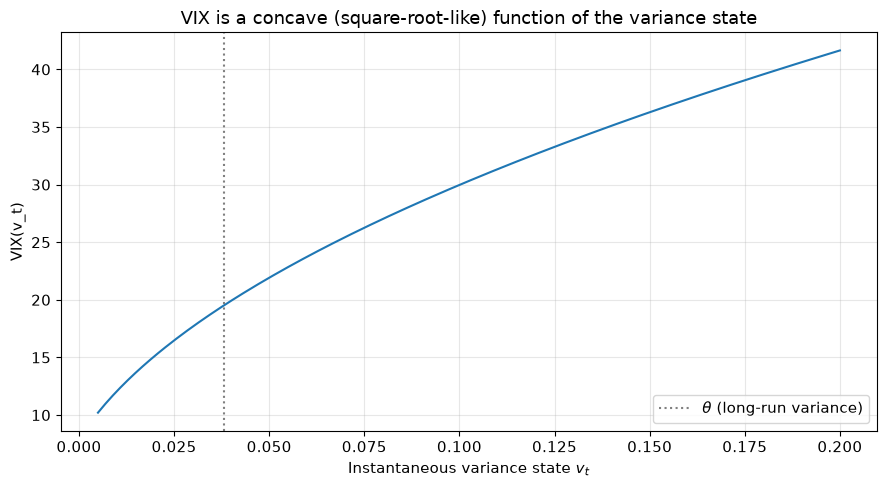

In [4]:
Delta_vix = 30 / 365

def vix_ab(kappa, theta, Delta):
    b = (1 - np.exp(-kappa * Delta)) / (kappa * Delta)
    a = theta * (1 - b)
    return a, b

def vix_from_variance_state(v, kappa, theta, Delta):
    a, b = vix_ab(kappa, theta, Delta)
    return 100 * np.sqrt(a + b * v)

a_vix, b_vix = vix_ab(kappa_h, theta_h, Delta_vix)
print(f"a = {a_vix:.6f}, b = {b_vix:.6f}")
print(f"VIX(v0) via transform: {vix_from_variance_state(v0_h, kappa_h, theta_h, Delta_vix):.4f}")
print(f"(matches the replication/analytic values above, as it must)")

v_grid = np.linspace(0.005, 0.20, 200)
fig, ax = plt.subplots()
ax.plot(v_grid, vix_from_variance_state(v_grid, kappa_h, theta_h, Delta_vix))
ax.axvline(theta_h, color="gray", ls=":", label=r"$\theta$ (long-run variance)")
ax.set_xlabel("Instantaneous variance state $v_t$"); ax.set_ylabel("VIX(v_t)")
ax.set_title("VIX is a concave (square-root-like) function of the variance state")
ax.legend()
plt.tight_layout(); plt.show()

## 3. Pricing VIX futures: Jensen's gap and the CIR approach

**Source:** Gruenbichler & Longstaff (1996), *Valuing Futures and Options on Volatility*, J.
Futures Markets, is the foundational closed-form treatment: model the volatility-relevant state
as a square-root (CIR) mean-reverting process and price its futures/options via the process's
known transition density. Zhu & Zhang (2007), *Variance Term Structure and VIX Futures
Pricing*, and Zhang & Zhu (2006) extend this specifically to VIX under Heston-consistent
variance dynamics — exactly the setup built in Section 2.

**The trap a junior trader falls into:** it's tempting to price the VX future as
$100\sqrt{\mathbb E^{\mathbb Q}[\text{variance}_T]}$ — plug the expected variance into the VIX
formula. That is *wrong*, because $\mathbb E[\sqrt{X}] \le \sqrt{\mathbb E[X]}$ for any
non-degenerate random $X$ (Jensen's inequality, since $\sqrt{\cdot}$ is concave). The correct
no-arbitrage price is $F_t(T) = \mathbb E^{\mathbb Q}_t[\text{VIX}_T] = \mathbb E^{\mathbb
Q}_t\big[100\sqrt{a+bv_T}\big]$, which is *strictly below* the naive plug-in — the gap is the
**volatility convexity adjustment**, and it is a real, tradeable mispricing if you get it
wrong.

We compute the correct expectation using the CIR process's own transition density, which is a
scaled noncentral chi-squared distribution (Cox, Ingersoll & Ross, 1985; used for exact
simulation by Broadie & Kaya, 2006):

$$
v_{t+\tau} \mid v_t \ \sim\ c\cdot\chi'^2_d(\lambda), \qquad
c = \frac{\xi^2(1-e^{-\kappa\tau})}{4\kappa}, \quad d = \frac{4\kappa\theta}{\xi^2}, \quad
\lambda = \frac{4\kappa e^{-\kappa\tau}v_t}{\xi^2(1-e^{-\kappa\tau})}
$$

so $F_t(T) = \mathbb E\big[100\sqrt{a+bc\,X}\big]$ for $X\sim\chi'^2_d(\lambda)$ — a one-dimensional
numerical integral against a known density, no simulation required for the point estimate. We
validate it against **exact** Monte Carlo simulation of the CIR process (sampling directly from
the noncentral chi-squared transition at each step — no Euler discretisation bias at all).

In [5]:
def cir_transition_params(kappa, theta, xi, v_t, tau):
    c = xi**2 * (1 - np.exp(-kappa * tau)) / (4 * kappa)
    d = 4 * kappa * theta / xi**2
    lam = 4 * kappa * np.exp(-kappa * tau) * v_t / (xi**2 * (1 - np.exp(-kappa * tau)))
    return c, d, lam

def vix_future_price_analytic(v_t, tau, kappa, theta, xi, Delta=Delta_vix):
    a, b = vix_ab(kappa, theta, Delta)
    if tau < 1e-8:
        return vix_from_variance_state(v_t, kappa, theta, Delta)
    c, d, lam = cir_transition_params(kappa, theta, xi, v_t, tau)
    dist = ncx2(d, lam)
    return 100 * dist.expect(lambda x: np.sqrt(np.maximum(a + b * c * x, 0.0)))

def vix_future_price_naive(v_t, tau, kappa, theta, xi, Delta=Delta_vix):
    # WRONG but instructive: plug E[v_T] straight into the VIX transform, ignoring convexity
    Ev_T = theta + (v_t - theta) * np.exp(-kappa * tau)
    return vix_from_variance_state(Ev_T, kappa, theta, Delta)

def cir_exact_mc(rng, v_t, tau, kappa, theta, xi, n_paths):
    c, d, lam = cir_transition_params(kappa, theta, xi, v_t, tau)
    X = rng.noncentral_chisquare(d, lam, size=n_paths)
    return c * X

rng = np.random.default_rng(42)
tau_test = 60 / 365
v_T_samples = cir_exact_mc(rng, v0_h, tau_test, kappa_h, theta_h, xi_h, n_paths=2_000_000)
a_v, b_v = vix_ab(kappa_h, theta_h, Delta_vix)
mc_price = 100 * np.mean(np.sqrt(a_v + b_v * v_T_samples))
mc_se = 100 * np.std(np.sqrt(a_v + b_v * v_T_samples)) / np.sqrt(len(v_T_samples))

analytic_price = vix_future_price_analytic(v0_h, tau_test, kappa_h, theta_h, xi_h)
naive_price = vix_future_price_naive(v0_h, tau_test, kappa_h, theta_h, xi_h)

print(f"2-month VX future -- exact CIR Monte Carlo:      {mc_price:.4f}  +/- {1.96*mc_se:.4f}")
print(f"2-month VX future -- semi-analytic (ncx2):        {analytic_price:.4f}")
print(f"2-month VX future -- naive plug-in (WRONG):       {naive_price:.4f}")
print(f"Convexity gap (naive - correct):                   {naive_price - analytic_price:.4f} vol points")
assert abs(mc_price - analytic_price) < 5 * mc_se
assert naive_price > analytic_price   # Jensen's inequality must bite this direction

2-month VX future -- exact CIR Monte Carlo:      18.4446  +/- 0.0088
2-month VX future -- semi-analytic (ncx2):        18.4429
2-month VX future -- naive plug-in (WRONG):       19.4936
Convexity gap (naive - correct):                   1.0507 vol points


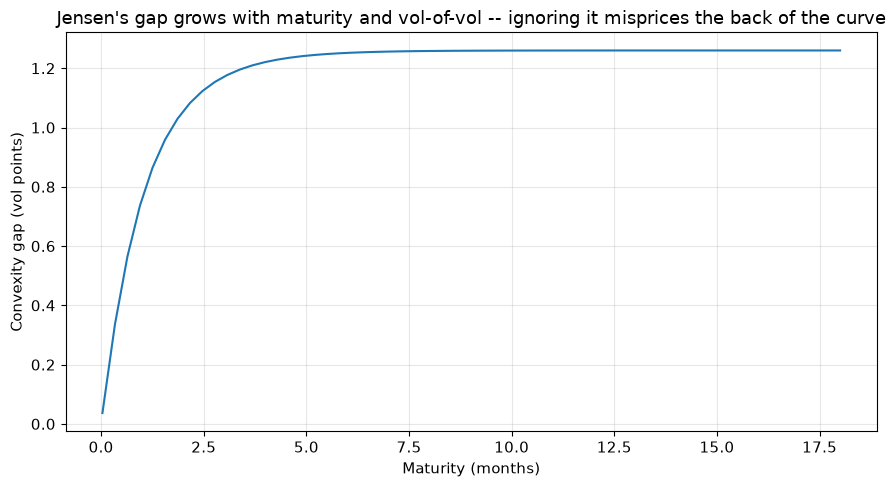

In [6]:
taus = np.linspace(1/365, 1.5, 60)
gaps = [vix_future_price_naive(v0_h, t, kappa_h, theta_h, xi_h) - vix_future_price_analytic(v0_h, t, kappa_h, theta_h, xi_h) for t in taus]

fig, ax = plt.subplots()
ax.plot(taus * 12, gaps)
ax.set_xlabel("Maturity (months)"); ax.set_ylabel("Convexity gap (vol points)")
ax.set_title("Jensen's gap grows with maturity and vol-of-vol -- ignoring it misprices the back of the curve")
plt.tight_layout(); plt.show()

### A note on speed: a precomputed pricing grid

`vix_future_price_analytic` does a numerical integration (`ncx2.expect`) *every single call* --
fine for a handful of quotes, far too slow for a Monte Carlo backtest that needs the price at
tens of thousands of $(v,\tau)$ points. The standard practitioner fix, used from here on, is to
evaluate the pricer once on a grid and interpolate: build a $(v,\tau)$ lookup table up front,
then every downstream simulation or backtest looks the price up instead of re-integrating. This
is the same tradeoff a real desk's real-time pricing library makes -- precompute the expensive
part, serve cheap interpolated lookups intraday.

In [7]:
v_nodes = np.linspace(0.002, 0.6, 90)
tau_nodes = np.linspace(1e-4, 1.0, 90)
price_table = np.array([[vix_future_price_analytic(v, t, kappa_h, theta_h, xi_h) for t in tau_nodes] for v in v_nodes])
price_interp = RegularGridInterpolator((v_nodes, tau_nodes), price_table, bounds_error=False, fill_value=None)

def fast_price(v_arr, tau_arr):
    v_arr, tau_arr = np.broadcast_arrays(np.asarray(v_arr, dtype=float), np.asarray(tau_arr, dtype=float))
    pts = np.column_stack([v_arr.ravel(), tau_arr.ravel()])
    return price_interp(pts).reshape(v_arr.shape)

# Sanity check: interpolated grid vs the exact semi-analytic price at a few spot-checks
for v_test, tau_test_ in [(0.02, 1/12), (0.16, 4/12), (0.038, 0.75)]:
    exact = vix_future_price_analytic(v_test, tau_test_, kappa_h, theta_h, xi_h)
    interp_val = float(fast_price(v_test, tau_test_))
    print(f"v={v_test:.3f}, tau={tau_test_:.3f}:  exact={exact:.4f}  interpolated={interp_val:.4f}  diff={abs(exact-interp_val):.4f}")
    assert abs(exact - interp_val) < 0.05

v=0.020, tau=0.083:  exact=15.9214  interpolated=15.9145  diff=0.0069
v=0.160, tau=0.333:  exact=23.1980  interpolated=23.1990  diff=0.0010
v=0.038, tau=0.750:  exact=18.2345  interpolated=18.2345  diff=0.0000


## 4. Building the term structure: contango, backwardation, roll yield

VIX mean-reverts around a long-run level $\sqrt\theta$. That single fact drives the two regimes
every VIX trader thinks in:

- **Contango** (the normal state, ~80% of trading days historically): spot VIX sits below the
  long-run level, so each successively deeper contract prices in more reversion *upward* toward
  $\sqrt\theta$ — the curve slopes up. Holding a long front-month future and rolling it forward
  before expiry is a structural headwind (you sell low, roll into higher-priced further-dated
  contracts) — this is exactly the mechanic that erodes long-volatility ETPs over time and
  funds the carry that short-vol strategies try to harvest.
- **Backwardation** (stress regime): spot VIX spikes above $\sqrt\theta$, so the curve slopes
  down — the market is pricing mean reversion *down* from an elevated level. This is the
  fingerprint of a live volatility event.

We build a full 9-contract VX strip under both regimes from the same model, changing only the
current variance state $v_0$ — nothing else about the model changes.

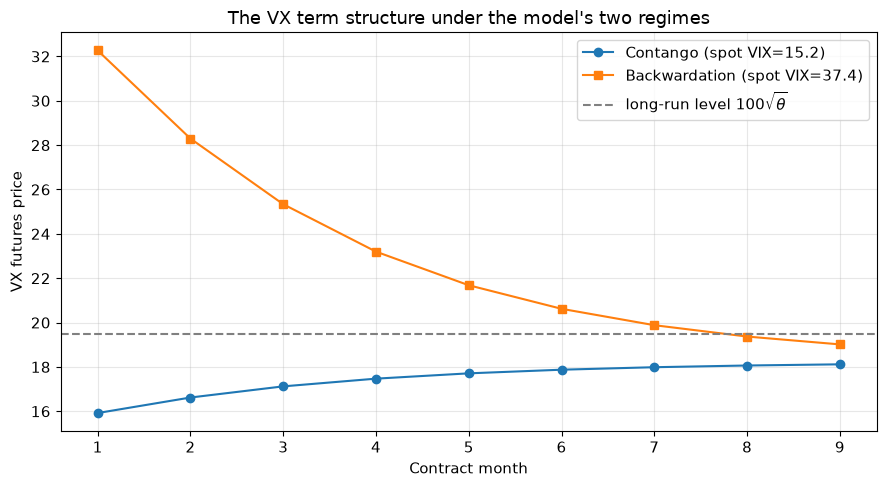

In [8]:
def build_term_structure(v0, kappa, theta, xi, maturities_months=range(1, 10)):
    taus = np.array([m / 12 for m in maturities_months])
    prices = np.array([vix_future_price_analytic(v0, t, kappa, theta, xi) for t in taus])
    return taus, prices

v0_contango = 0.020      # spot vol ~ sqrt(0.02) ~ 14%, below long-run 19.5%
v0_backwardation = 0.16  # spot vol ~ 40%, a stress spike

taus_c, prices_c = build_term_structure(v0_contango, kappa_h, theta_h, xi_h)
taus_b, prices_b = build_term_structure(v0_backwardation, kappa_h, theta_h, xi_h)

fig, ax = plt.subplots()
ax.plot(np.array(list(range(1, 10))), prices_c, "o-", label=f"Contango (spot VIX={vix_from_variance_state(v0_contango, kappa_h, theta_h, Delta_vix):.1f})")
ax.plot(np.array(list(range(1, 10))), prices_b, "s-", label=f"Backwardation (spot VIX={vix_from_variance_state(v0_backwardation, kappa_h, theta_h, Delta_vix):.1f})")
ax.axhline(100 * np.sqrt(theta_h), color="gray", ls="--", label=r"long-run level $100\sqrt{\theta}$")
ax.set_xlabel("Contract month"); ax.set_ylabel("VX futures price")
ax.set_title("The VX term structure under the model's two regimes")
ax.legend()
plt.tight_layout(); plt.show()

In [9]:
def roll_yield(prices, taus):
    # annualised roll yield of holding the front contract and rolling into the next, in % per month
    return (prices[:-1] - prices[1:]) / prices[1:] * 100

ry_c = roll_yield(prices_c, taus_c)
ry_b = roll_yield(prices_b, taus_b)
df_roll = pd.DataFrame({"month_pair": [f"{i+1}->{i+2}" for i in range(8)],
                          "roll_yield_contango_%": ry_c, "roll_yield_backwardation_%": ry_b})
df_roll

,month_pair,roll_yield_contango_%,roll_yield_backwardation_%
0,1->2,-4.209318,14.041786
1,2->3,-2.936215,11.679190
2,3->4,-1.992495,9.217283
3,4->5,-1.349988,6.989651
4,5->6,-0.917198,5.149466
5,6->7,-0.625029,3.716153
6,7->8,-0.426966,2.642689
7,8->9,-0.292194,1.859926


## 5. VIX futures "Greeks": variance-delta and the bucket ladder

Every VX contract's price is a function $F_t(T) = f(v_t, T-t)$ of a *single* underlying state
variable, so its risk is fully summarised by:

$$
\Delta^{\text{var}}_i = \frac{\partial F_t(T_i)}{\partial v_t}
$$

This is the number a market maker actually hedges: it tells you how many dollars each contract
in the strip moves per unit move in the (unobservable, but inferable) variance state — the VIX
futures analogue of a bond's DV01 against a single yield-curve factor. Because every contract
loads on the *same* state variable, the whole 9-contract book's variance risk collapses to a
single number (the sum of $\Delta^{\text{var}}_i \times$ position), which is exactly why a VX
desk can hedge a lopsided strip position with just one or two other maturities rather than
needing an SPX option overlay for every bucket.

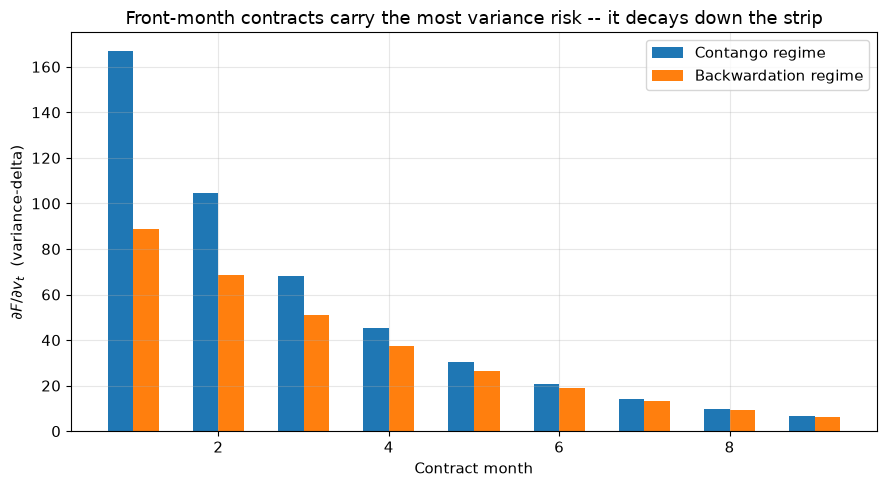

Note: variance-delta is largest and most convex near expiry -- the front contract is where a
market maker's overnight risk concentrates, which is exactly why front-month liquidity is deepest.


In [10]:
def variance_delta(v0, tau, kappa, theta, xi, h=1e-4):
    up = vix_future_price_analytic(v0 + h, tau, kappa, theta, xi)
    dn = vix_future_price_analytic(v0 - h, tau, kappa, theta, xi)
    return (up - dn) / (2 * h)

months = np.arange(1, 10)
deltas_contango = [variance_delta(v0_contango, m / 12, kappa_h, theta_h, xi_h) for m in months]
deltas_backward = [variance_delta(v0_backwardation, m / 12, kappa_h, theta_h, xi_h) for m in months]

fig, ax = plt.subplots()
ax.bar(months - 0.15, deltas_contango, width=0.3, label="Contango regime")
ax.bar(months + 0.15, deltas_backward, width=0.3, label="Backwardation regime")
ax.set_xlabel("Contract month"); ax.set_ylabel(r"$\partial F/\partial v_t$  (variance-delta)")
ax.set_title("Front-month contracts carry the most variance risk -- it decays down the strip")
ax.legend()
plt.tight_layout(); plt.show()
print("Note: variance-delta is largest and most convex near expiry -- the front contract is where a")
print("market maker's overnight risk concentrates, which is exactly why front-month liquidity is deepest.")

## 6. Market making the book: Avellaneda-Stoikov inventory quoting

**Source:** Avellaneda & Stoikov (2008), *High-Frequency Trading in a Limit Order Book*,
Quantitative Finance. The classic inventory-risk market-making model. A dealer holding
inventory $q$ in an asset with mid-price $s$, risk aversion $\gamma$, facing exponentially-decaying
order-arrival intensity $\lambda(\delta) = A e^{-k\delta}$ at a quote distance $\delta$ from
mid, should not quote symmetrically around the mid. Instead, quote around a **reservation
price** that skews away from the inventory you're already carrying (so you're less eager to
add to it and more eager to unwind it):

$$
r(s,q,t) = s - q\,\gamma\,\sigma^2\,(T-t)
$$

with total optimal spread

$$
\delta_{\text{bid}} + \delta_{\text{ask}} = \gamma\sigma^2(T-t) + \frac{2}{\gamma}\ln\!\left(1+\frac{\gamma}{k}\right)
$$

split symmetrically around $r$. Intuitively: the higher your inventory risk ($\gamma$, $\sigma$,
time left) and the more inventory you're holding, the more your quotes shade away from the mid
to reduce it. We simulate a front-month VX contract's mid-price using the *exact* CIR simulation
from Section 3 (so the price path has genuine mean-reversion and vol-of-vol, not generic GBM),
run a Poisson order-arrival process against Avellaneda-Stoikov quotes, and compare to a naive
market maker who always quotes a fixed symmetric spread with no inventory awareness.

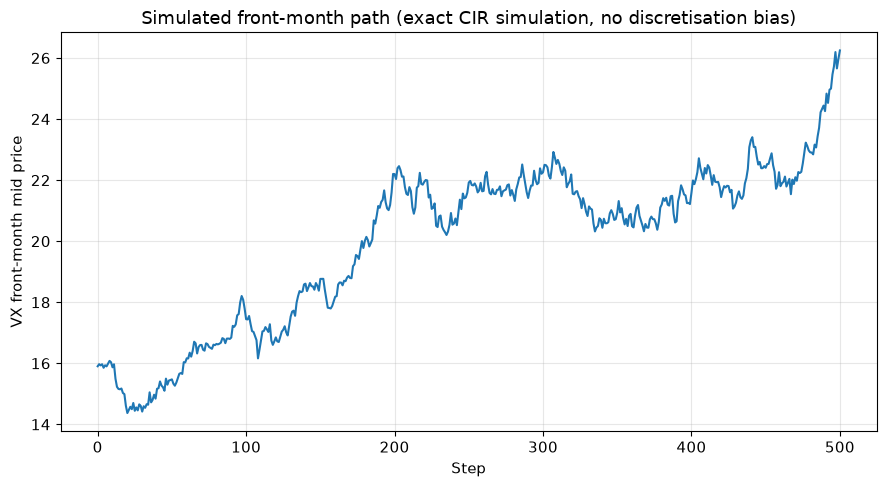

In [11]:
def simulate_futures_path(v0, tau0, kappa, theta, xi, n_steps, rng, price_grid_interp):
    dt = tau0 / n_steps
    v_path = np.empty(n_steps + 1)
    v_path[0] = v0
    for i in range(n_steps):
        v_path[i+1] = cir_exact_mc(rng, v_path[i], dt, kappa, theta, xi, n_paths=1)[0]
    remaining_tau = tau0 - dt * np.arange(n_steps + 1)
    remaining_tau = np.maximum(remaining_tau, 1e-6)
    prices = price_grid_interp(np.column_stack([v_path, remaining_tau]))
    return prices, v_path

# Reuses the price_interp grid built in Section 3 -- no need to rebuild it here
rng = np.random.default_rng(3)
n_steps = 500
tau0 = 30 / 365    # simulate the last month of a front-month contract's life, trading-day granularity
mid_path, v_path = simulate_futures_path(v0_contango, tau0, kappa_h, theta_h, xi_h, n_steps, rng, price_interp)

fig, ax = plt.subplots()
ax.plot(mid_path)
ax.set_xlabel("Step"); ax.set_ylabel("VX front-month mid price")
ax.set_title("Simulated front-month path (exact CIR simulation, no discretisation bias)")
plt.tight_layout(); plt.show()

In [12]:
def run_market_maker(mid_path, gamma, k_intensity, A_intensity, sigma_est, T_horizon, inventory_aware, rng, tick=0.05):
    n = len(mid_path)
    dt = T_horizon / (n - 1)
    cash, inventory = 0.0, 0
    inventory_hist, pnl_hist = np.zeros(n), np.zeros(n)

    for t in range(n - 1):
        s = mid_path[t]
        time_left = T_horizon - t * dt
        if inventory_aware:
            r_res = s - inventory * gamma * sigma_est**2 * time_left
            half_spread = 0.5 * (gamma * sigma_est**2 * time_left + (2 / gamma) * np.log(1 + gamma / k_intensity))
        else:
            r_res = s
            half_spread = 0.5 * 0.10   # fixed 10-cent spread, no inventory skew

        half_spread = max(half_spread, tick)
        bid, ask = r_res - half_spread, r_res + half_spread
        delta_bid, delta_ask = s - bid, ask - s

        lam_bid = A_intensity * np.exp(-k_intensity * delta_bid)
        lam_ask = A_intensity * np.exp(-k_intensity * delta_ask)
        p_fill_bid = 1 - np.exp(-lam_bid * dt)
        p_fill_ask = 1 - np.exp(-lam_ask * dt)

        if rng.random() < p_fill_bid:
            inventory += 1
            cash -= bid
        if rng.random() < p_fill_ask:
            inventory -= 1
            cash += ask

        inventory_hist[t+1] = inventory
        pnl_hist[t+1] = cash + inventory * mid_path[t+1]

    # liquidate any residual inventory at the final mid to compare strategies on a level footing
    pnl_hist[-1] = cash + inventory * mid_path[-1]
    return pnl_hist, inventory_hist

gamma, k_intensity, A_intensity = 0.1, 40.0, 140.0
sigma_est = np.std(np.diff(mid_path)) / np.sqrt(tau0 / n_steps)

n_sims = 400
final_pnl_aware, final_pnl_naive = np.zeros(n_sims), np.zeros(n_sims)
max_abs_inv_aware, max_abs_inv_naive = np.zeros(n_sims), np.zeros(n_sims)

for i in range(n_sims):
    sim_rng = np.random.default_rng(1000 + i)
    path_rng = np.random.default_rng(2000 + i)
    sim_mid, _ = simulate_futures_path(v0_contango, tau0, kappa_h, theta_h, xi_h, n_steps, path_rng, price_interp)

    pnl_a, inv_a = run_market_maker(sim_mid, gamma, k_intensity, A_intensity, sigma_est, tau0, True, sim_rng)
    pnl_n, inv_n = run_market_maker(sim_mid, gamma, k_intensity, A_intensity, sigma_est, tau0, False, np.random.default_rng(1000 + i))

    final_pnl_aware[i], final_pnl_naive[i] = pnl_a[-1], pnl_n[-1]
    max_abs_inv_aware[i], max_abs_inv_naive[i] = np.max(np.abs(inv_a)), np.max(np.abs(inv_n))

print(f"Inventory-aware (Avellaneda-Stoikov): mean P&L={final_pnl_aware.mean():.3f}  std={final_pnl_aware.std():.3f}  mean max |inventory|={max_abs_inv_aware.mean():.1f}")
print(f"Naive fixed-spread, no skew:            mean P&L={final_pnl_naive.mean():.3f}  std={final_pnl_naive.std():.3f}  mean max |inventory|={max_abs_inv_naive.mean():.1f}")
print(f"P&L Sharpe (aware):  {final_pnl_aware.mean()/final_pnl_aware.std():.3f}")
print(f"P&L Sharpe (naive):  {final_pnl_naive.mean()/final_pnl_naive.std():.3f}")

Inventory-aware (Avellaneda-Stoikov): mean P&L=0.012  std=0.289  mean max |inventory|=0.1
Naive fixed-spread, no skew:            mean P&L=0.172  std=7.142  mean max |inventory|=1.8
P&L Sharpe (aware):  0.042
P&L Sharpe (naive):  0.024


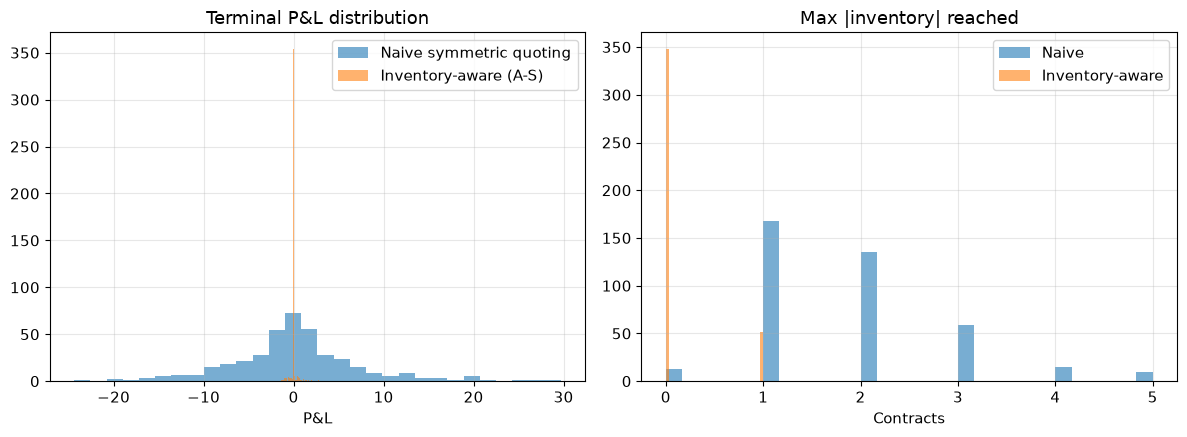

Inventory-aware quoting trades a little mean P&L for materially lower inventory risk --
exactly the tradeoff a risk desk enforces on a real market maker's book.


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(final_pnl_naive, bins=30, alpha=0.6, label="Naive symmetric quoting")
axes[0].hist(final_pnl_aware, bins=30, alpha=0.6, label="Inventory-aware (A-S)")
axes[0].set_title("Terminal P&L distribution"); axes[0].legend(); axes[0].set_xlabel("P&L")

axes[1].hist(max_abs_inv_naive, bins=30, alpha=0.6, label="Naive")
axes[1].hist(max_abs_inv_aware, bins=30, alpha=0.6, label="Inventory-aware")
axes[1].set_title("Max |inventory| reached"); axes[1].legend(); axes[1].set_xlabel("Contracts")
plt.tight_layout(); plt.show()
print("Inventory-aware quoting trades a little mean P&L for materially lower inventory risk --")
print("exactly the tradeoff a risk desk enforces on a real market maker's book.")

## 7. Trading the curve

### 7a. Systematic roll-yield carry

The textbook short-vol carry trade: short the front-month VX future (or a constant-maturity
blend) whenever the curve is in contango, collecting the roll yield computed in Section 4, and
flatten or flip when the curve inverts into backwardation. We backtest this on an *ensemble* of
independently simulated variance-state paths (each path is one "trading regime episode" — this
notebook does not have access to real historical VX prints, so the backtest is a Monte Carlo
stress test of the strategy against the model, not a historical replay).

In [14]:
def simulate_regime_episodes(v0, kappa, theta, xi, n_days, n_episodes, rng):
    # Vectorized across episodes: one Python-level loop over days, not over (day, episode) pairs.
    # Each step samples exactly from the CIR transition density (Cox-Ingersoll-Ross 1985), so
    # there is no Euler discretisation bias even though we're stepping day by day.
    dt = 1 / 365
    v_paths = np.empty((n_episodes, n_days + 1))
    v_paths[:, 0] = v0
    for day in range(n_days):
        c, d, lam = cir_transition_params(kappa, theta, xi, v_paths[:, day], dt)
        v_paths[:, day + 1] = c * rng.noncentral_chisquare(d, lam)
    return v_paths

def curve_slope(v_arr, near_m=1, far_m=4):
    near = fast_price(v_arr, near_m / 12)
    far = fast_price(v_arr, far_m / 12)
    return (far - near) / near   # positive = contango

def backtest_carry_strategy(v0, kappa, theta, xi, n_days, n_episodes, filter_backwardation, seed=0):
    rng = np.random.default_rng(seed)
    v_paths = simulate_regime_episodes(v0, kappa, theta, xi, n_days, n_episodes, rng)
    front = fast_price(v_paths, 1 / 12)
    slopes = curve_slope(v_paths)

    position = np.where(slopes > 0, -1, 0) if filter_backwardation else -np.ones_like(v_paths)
    # daily P&L of shorting the (roll-adjusted) front future: -(change in front price) * position
    daily_pnl = -np.diff(front, axis=1) * position[:, :-1]
    return daily_pnl

n_days, n_episodes = 90, 300
pnl_naive_short = backtest_carry_strategy(v0_contango, kappa_h, theta_h, xi_h, n_days, n_episodes, filter_backwardation=False, seed=7)
pnl_filtered = backtest_carry_strategy(v0_contango, kappa_h, theta_h, xi_h, n_days, n_episodes, filter_backwardation=True, seed=7)

def strategy_stats(pnl_matrix, label):
    total = pnl_matrix.sum(axis=1)
    sharpe = total.mean() / total.std() * np.sqrt(365 / n_days)
    cum = np.cumsum(pnl_matrix, axis=1)
    max_dd = np.min(cum - np.maximum.accumulate(cum, axis=1))
    print(f"{label}: mean episode P&L={total.mean():.3f}  std={total.std():.3f}  ann.Sharpe={sharpe:.2f}  worst drawdown seen={max_dd:.3f}")
    return total

total_naive = strategy_stats(pnl_naive_short, "Always short front-month (naive carry)")
total_filtered = strategy_stats(pnl_filtered, "Short only in contango, flat in backwardation (filtered)")

Always short front-month (naive carry): mean episode P&L=1.964  std=4.485  ann.Sharpe=0.88  worst drawdown seen=-14.564
Short only in contango, flat in backwardation (filtered): mean episode P&L=2.509  std=3.169  ann.Sharpe=1.59  worst drawdown seen=-5.767


### 7b. Stress-testing the carry trade: a Volmageddon-style jump

Both variants above are backtested against ordinary CIR dynamics — smooth mean reversion, no
sudden jumps. Real vol spikes are not smooth: the CIR diffusion alone understates tail risk.
We inject a rare, large upward jump in the variance state partway through each episode (a
crude but effective stand-in for a real vol-spike day) and see how the naive always-short
strategy compares to the backwardation-filtered one when the tail event actually happens.

Naive carry, WITH tail-jump risk: mean episode P&L=2.069  std=5.303  ann.Sharpe=0.79  worst drawdown seen=-14.755
Backwardation-filtered carry, WITH tail-jump risk: mean episode P&L=3.435  std=5.597  ann.Sharpe=1.24  worst drawdown seen=-5.738


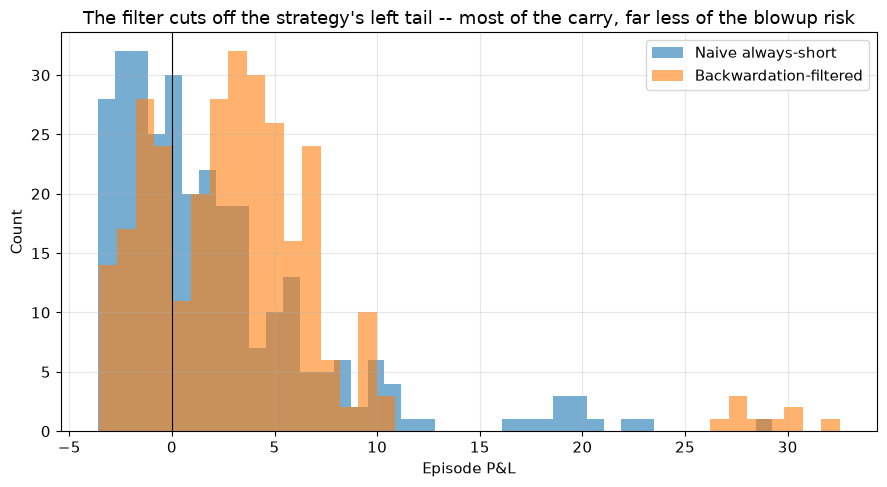


Worst single episode, naive:     -3.617
Worst single episode, filtered:  -3.571


In [15]:
def backtest_carry_with_jump(v0, kappa, theta, xi, n_days, n_episodes, filter_backwardation,
                               jump_prob, jump_size, seed=0):
    rng = np.random.default_rng(seed)
    v_paths = simulate_regime_episodes(v0, kappa, theta, xi, n_days, n_episodes, rng)

    jump_day = n_days // 2
    jump_mask = rng.random(n_episodes) < jump_prob
    decay = np.exp(-kappa * (np.arange(n_days + 1 - jump_day) / 365))
    v_paths[jump_mask, jump_day:] += jump_size * decay[np.newaxis, :]

    front = fast_price(v_paths, 1 / 12)
    slopes = curve_slope(v_paths)
    position = np.where(slopes > 0, -1, 0) if filter_backwardation else -np.ones_like(v_paths)
    daily_pnl = -np.diff(front, axis=1) * position[:, :-1]
    return daily_pnl

jump_prob, jump_size = 0.05, 0.30   # 5% chance per episode of a variance jump of +0.30 (spot vol spikes hard)
pnl_naive_jump = backtest_carry_with_jump(v0_contango, kappa_h, theta_h, xi_h, n_days, n_episodes, False, jump_prob, jump_size, seed=99)
pnl_filtered_jump = backtest_carry_with_jump(v0_contango, kappa_h, theta_h, xi_h, n_days, n_episodes, True, jump_prob, jump_size, seed=99)

total_naive_jump = strategy_stats(pnl_naive_jump, "Naive carry, WITH tail-jump risk")
total_filtered_jump = strategy_stats(pnl_filtered_jump, "Backwardation-filtered carry, WITH tail-jump risk")

fig, ax = plt.subplots()
ax.hist(total_naive_jump, bins=40, alpha=0.6, label="Naive always-short")
ax.hist(total_filtered_jump, bins=40, alpha=0.6, label="Backwardation-filtered")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Episode P&L"); ax.set_ylabel("Count"); ax.legend()
ax.set_title("The filter cuts off the strategy's left tail -- most of the carry, far less of the blowup risk")
plt.tight_layout(); plt.show()

print(f"\nWorst single episode, naive:     {total_naive_jump.min():.3f}")
print(f"Worst single episode, filtered:  {total_filtered_jump.min():.3f}")

### 7c. Calendar spread mean reversion

A calendar spread (long one maturity, short another) isolates curve *shape* risk from the
outright level. Because the curve slope in this model is itself a deterministic, mean-reverting
function of $v_t$, an extreme slope reading is a bet that $v_t$ (and hence the slope) reverts —
we trade the slope's z-score directly against its own simulated distribution.

In [16]:
def backtest_calendar_spread(v0, kappa, theta, xi, n_days, n_episodes, seed=0, z_entry=1.0):
    rng = np.random.default_rng(seed)
    v_paths = simulate_regime_episodes(v0, kappa, theta, xi, n_days, n_episodes, rng)

    near = fast_price(v_paths, 1 / 12)
    far = fast_price(v_paths, 4 / 12)
    spread = far - near
    z = (spread - spread.mean(axis=1, keepdims=True)) / spread.std(axis=1, keepdims=True)

    position = np.where(z > z_entry, -1, np.where(z < -z_entry, 1, 0))   # fade extreme slope
    daily_pnl = np.diff(spread, axis=1) * position[:, :-1]
    return daily_pnl

pnl_calendar = backtest_calendar_spread(v0_contango, kappa_h, theta_h, xi_h, n_days, n_episodes, seed=21)
total_calendar = strategy_stats(pnl_calendar, "Calendar-spread mean reversion (fade |z|>1 slope)")

Calendar-spread mean reversion (fade |z|>1 slope): mean episode P&L=3.994  std=2.242  ann.Sharpe=3.59  worst drawdown seen=-4.506


## 8. Risk management: hedging a strip

A market maker rarely holds a single VX contract; the book is a strip of positions across
several months. Because every contract's risk is a variance-delta on the *same* underlying
state, hedging the strip reduces to matching the *sum* of variance-deltas, not each leg
individually. We size a hedge in one liquid contract (say month 3) against an arbitrary
front-heavy book to flatten net variance-delta, then confirm the hedged book's P&L is far less
sensitive to a shock in $v_t$ than the unhedged book.

Unhedged book net variance-delta: 2428.83
Hedge: -35.72 contracts of the 3-month future
Hedged book net variance-delta:   -0.000000


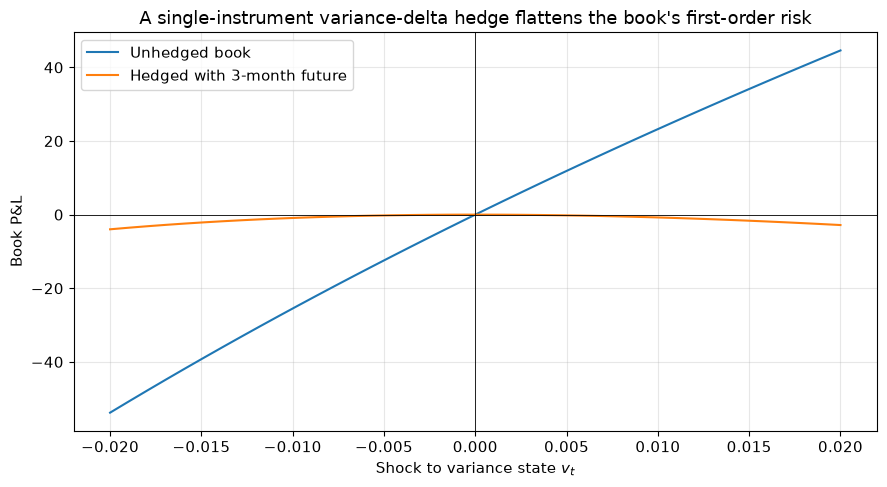

In [17]:
book_positions = {1: 20, 2: -10, 3: 5, 5: -8, 7: 3}   # month: number of contracts (+ long, - short)

def book_variance_delta(positions, v0, kappa, theta, xi):
    return sum(qty * variance_delta(v0, m / 12, kappa, theta, xi) for m, qty in positions.items())

net_delta_unhedged = book_variance_delta(book_positions, v0_contango, kappa_h, theta_h, xi_h)
hedge_instrument_month = 3
hedge_delta_per_contract = variance_delta(v0_contango, hedge_instrument_month / 12, kappa_h, theta_h, xi_h)
hedge_qty = -net_delta_unhedged / hedge_delta_per_contract

hedged_positions = dict(book_positions)
hedged_positions[hedge_instrument_month] = hedged_positions.get(hedge_instrument_month, 0) + hedge_qty
net_delta_hedged = book_variance_delta(hedged_positions, v0_contango, kappa_h, theta_h, xi_h)

print(f"Unhedged book net variance-delta: {net_delta_unhedged:.2f}")
print(f"Hedge: {hedge_qty:.2f} contracts of the {hedge_instrument_month}-month future")
print(f"Hedged book net variance-delta:   {net_delta_hedged:.6f}")

def book_pnl_for_shock(positions, v0, shock, kappa, theta, xi):
    p0 = sum(qty * vix_future_price_analytic(v0, m / 12, kappa, theta, xi) for m, qty in positions.items())
    p1 = sum(qty * vix_future_price_analytic(v0 + shock, m / 12, kappa, theta, xi) for m, qty in positions.items())
    return p1 - p0

shocks = np.linspace(-0.02, 0.02, 40)
pnl_unhedged = [book_pnl_for_shock(book_positions, v0_contango, s, kappa_h, theta_h, xi_h) for s in shocks]
pnl_hedged = [book_pnl_for_shock(hedged_positions, v0_contango, s, kappa_h, theta_h, xi_h) for s in shocks]

fig, ax = plt.subplots()
ax.plot(shocks, pnl_unhedged, label="Unhedged book")
ax.plot(shocks, pnl_hedged, label=f"Hedged with {hedge_instrument_month}-month future")
ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
ax.set_xlabel("Shock to variance state $v_t$"); ax.set_ylabel("Book P&L")
ax.legend(); ax.set_title("A single-instrument variance-delta hedge flattens the book's first-order risk")
plt.tight_layout(); plt.show()

## 9. Case study: Volmageddon, February 5, 2018

On February 5, 2018, VIX spiked roughly 100-115% intraday (from the mid-teens to close near
37), the largest one-day jump in the index's history at the time. The proximate mechanism was a
feedback loop: short-volatility exchange-traded products (notably VelocityShares' XIV and
ProShares' SVXY) were structurally short VX futures to deliver inverse daily exposure to VIX,
and were contractually obligated to rebalance — buy back VX futures — as VIX rose, in
proportion to the day's move. As VIX moved sharply intraday, the required rebalancing hedge
itself was large enough, relative to VX futures liquidity, to push the front-month future
further, which increased the required rebalance further still. XIV lost essentially all of its
value overnight and was terminated by its issuer (Credit Suisse) days later; SVXY suffered
comparable losses and was restructured to a lower target leverage afterward. See Cboe's and the
CFTC/SEC staff post-mortems, and academic treatments such as Alexander & Korovilas' and related
work on volatility-linked ETP mechanics, for detailed accounts.

**Why this notebook's tail-risk test in Section 7b is the right shape of lesson, even though it
isn't a historical replay:** the naive always-short-front-month strategy is structurally
*exactly* what XIV/SVXY were doing, systematically, every day. The backwardation filter is a
crude proxy for the kind of risk control (position sizing that reacts to curve shape, not just
level) that a "structurally short gamma on vol-of-vol" product cannot apply, because its
mandate is to always be short a fixed multiple regardless of the curve. The lesson generalises
beyond this one event: **any strategy that is short vega with a rigid, non-discretionary sizing
rule is exposed to the same feedback mechanism, at a scale set by how much industry AUM is
positioned the same way.**

## 10. Model comparison and references

In [18]:
comparison = pd.DataFrame([
    ["CBOE model-free variance replication", "Static option-strip integral", "Real-time index calc", "Computing the VIX print itself from a live SPX/SPXW chain", "Needs a full, liquid strike ladder; sensitive to wing liquidity"],
    ["Naive sqrt(E[Var]) futures pricing", "Plug-in, no convexity", "Instant, wrong", "Never -- included only to show the Jensen's-gap error", "Systematically overprices the future; a real arbitrage if traded on"],
    ["Gruenbichler-Longstaff / CIR (ncx2)", "Semi-analytic (known transition density)", "Fast (ms)", "Fair-value VX pricing, term structure, variance-delta ladders", "Single-factor variance state; real vol has richer term-structure factors"],
    ["Exact CIR simulation (Broadie-Kaya style)", "Monte Carlo, exact transition sampling", "Moderate", "Validating the semi-analytic price; path-dependent VIX-derivative payoffs", "Slower than the closed-form point estimate; still single-factor"],
    ["Avellaneda-Stoikov inventory quoting", "Closed-form optimal quotes", "Instant per quote", "Setting bid/ask and skew on a live book given inventory", "Assumes Poisson fills and a known vol estimate; real flow is lumpier"],
], columns=["Model / method", "Approach", "Typical speed", "Best used for", "Main limitation"])

pd.set_option("display.max_colwidth", 65)
comparison

,Model / method,Approach,Typical speed,Best used for,Main limitation
0,CBOE model-free variance replication,Static option-strip integral,Real-time index calc,Computing the VIX print itself from a live SPX/SPXW chain,"Needs a full, liquid strike ladder; sensitive to wing liquidity"
1,Naive sqrt(E[Var]) futures pricing,"Plug-in, no convexity","Instant, wrong",Never -- included only to show the Jensen's-gap error,Systematically overprices the future; a real arbitrage if tra...
2,Gruenbichler-Longstaff / CIR (ncx2),Semi-analytic (known transition density),Fast (ms),"Fair-value VX pricing, term structure, variance-delta ladders",Single-factor variance state; real vol has richer term-struct...
3,Exact CIR simulation (Broadie-Kaya style),"Monte Carlo, exact transition sampling",Moderate,Validating the semi-analytic price; path-dependent VIX-deriva...,Slower than the closed-form point estimate; still single-factor
4,Avellaneda-Stoikov inventory quoting,Closed-form optimal quotes,Instant per quote,Setting bid/ask and skew on a live book given inventory,Assumes Poisson fills and a known vol estimate; real flow is ...


### References

1. Cboe Exchange (2003, updated 2019). *Cboe Volatility Index (VIX) White Paper*.
2. Britten-Jones, M. & Neuberger, A. (2000). *Option Prices, Implied Price Processes, and Stochastic Volatility*. Journal of Finance, 55(2), 839-866.
3. Demeterfi, K., Derman, E., Kamal, M. & Zou, J. (1999). *More Than You Ever Wanted to Know About Volatility Swaps*. Goldman Sachs Quantitative Strategies Research Notes.
4. Whaley, R. E. (1993). *Derivatives on Market Volatility: Hedging Tools Long Overdue*. Journal of Derivatives, 1(1), 71-84.
5. Heston, S. L. (1993). *A Closed-Form Solution for Options with Stochastic Volatility*. Review of Financial Studies, 6(2), 327-343.
6. Cox, J. C., Ingersoll, J. E. & Ross, S. A. (1985). *A Theory of the Term Structure of Interest Rates*. Econometrica, 53(2), 385-407.
7. Gruenbichler, A. & Longstaff, F. A. (1996). *Valuing Futures and Options on Volatility*. Journal of Futures Markets, 16(9), 985-1001.
8. Zhang, J. E. & Zhu, Y. (2006). *VIX Futures*. Journal of Futures Markets, 26(6), 521-531.
9. Zhu, Y. & Zhang, J. E. (2007). *Variance Term Structure and VIX Futures Pricing*. International Journal of Theoretical and Applied Finance, 10(1), 111-127.
10. Broadie, M. & Kaya, Ö. (2006). *Exact Simulation of Stochastic Volatility and Other Affine Jump Diffusion Processes*. Operations Research, 54(2), 217-231.
11. Avellaneda, M. & Stoikov, S. (2008). *High-Frequency Trading in a Limit Order Book*. Quantitative Finance, 8(3), 217-224.
12. Egloff, D., Leippold, M. & Wu, L. (2010). *The Term Structure of Variance Swap Rates and Optimal Variance Swap Investments*. Journal of Financial and Quantitative Analysis, 45(5), 1279-1310.
13. Carr, P. & Wu, L. (2006). *A Tale of Two Indices*. Journal of Derivatives, 13(3), 13-29.
14. Cboe Exchange staff / industry post-mortems on the February 5, 2018 volatility event ("Volmageddon"); see also Cboe's public commentary on VIX-linked ETP mechanics.